## Part 1: CNN


In [1]:
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms, models

In [2]:
from pathlib import Path
import torch

base_dir = Path('workshops/7/Cats_and_Dogs')
train = base_dir / 'train'
val = base_dir / 'val'
test = base_dir / 'test'

img_width, img_height, channels = 150, 150, 3
input_shape = (3, img_height, img_width)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

batch_size = 32


Using device: cuda


In [3]:
# Define transforms for data preprocessing
imagenet_mean = [0.485, 0.456, 0.406]
imagenet_std = [0.229, 0.224, 0.225]

data_transforms = {
    'train': transforms.Compose([
        transforms.RandomResizedCrop((img_width, img_height), scale=(0.7, 1.0)),
        transforms.RandomHorizontalFlip(),
        transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.05),
        transforms.ToTensor(),
        transforms.Normalize(imagenet_mean, imagenet_std),
    ]),
    'val': transforms.Compose([
        transforms.Resize((img_width, img_height)),
        transforms.ToTensor(),
        transforms.Normalize(imagenet_mean, imagenet_std),
    ]),
    'test': transforms.Compose([
        transforms.Resize((img_width, img_height)),
        transforms.ToTensor(),
        transforms.Normalize(imagenet_mean, imagenet_std),
    ]),
}

train_dataset = datasets.ImageFolder(train, transform=data_transforms['train'])
val_dataset = datasets.ImageFolder(val, transform=data_transforms['val'])
test_dataset = datasets.ImageFolder(test, transform=data_transforms['test'])

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=4,
                          pin_memory=True, persistent_workers=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, num_workers=4,
                        pin_memory=True, persistent_workers=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=4,
                         pin_memory=True, persistent_workers=True)

print(f"Train: {len(train_dataset)}, Val: {len(val_dataset)}, Test: {len(test_dataset)}")


Train: 20000, Val: 2490, Test: 2500


In [4]:
# Define CNN model: exactly 3 convolutional layers (as required), with BatchNorm
import torch.nn as nn


class CNNModel(nn.Module):
    """CNN with 3 convolutional layers for binary classification.

    BatchNorm stabilises training, global average pooling replaces the huge
    fully-connected layer (fewer parameters, less overfitting).
    """

    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            # conv layer 1
            nn.Conv2d(3, 32, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2, 2),
            # conv layer 2
            nn.Conv2d(32, 64, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2, 2),
            # conv layer 3
            nn.Conv2d(64, 128, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2, 2),
        )
        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
            nn.Dropout(0.4),
            nn.Linear(128, 1),
        )

    def forward(self, x):
        return self.classifier(self.features(x))


model = CNNModel().to(device)
print(model)


CNNModel(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU(inplace=True)
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): ReLU(inplace=True)
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): AdaptiveAvgPool2d(outpu

In [5]:
# Define loss function and optimizer
# Binary Cross Entropy with Logits (combines Sigmoid and BCE for better numerical stability)
criterion = nn.BCEWithLogitsLoss()

num_epochs = 30
optimizer = optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=num_epochs)
scaler = torch.amp.GradScaler('cuda', enabled=device.type == 'cuda')


In [6]:
# Training loop for PyTorch

train_losses = []
train_accuracies = []
val_losses = []
val_accuracies = []

use_amp = device.type == 'cuda'

for epoch in range(num_epochs):
    # Training phase
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True).float().unsqueeze(1)

        optimizer.zero_grad(set_to_none=True)
        with torch.amp.autocast('cuda', enabled=use_amp):
            outputs = model(images)
            loss = criterion(outputs, labels)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        running_loss += loss.item()
        predicted = (torch.sigmoid(outputs.float()) > 0.5).float()
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    scheduler.step()

    train_loss = running_loss / len(train_loader)
    train_acc = 100 * correct / total
    train_losses.append(train_loss)
    train_accuracies.append(train_acc)

    # Validation phase
    model.eval()
    val_running_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True).float().unsqueeze(1)

            with torch.amp.autocast('cuda', enabled=use_amp):
                outputs = model(images)
                loss = criterion(outputs, labels)

            val_running_loss += loss.item()
            predicted = (torch.sigmoid(outputs.float()) > 0.5).float()
            val_total += labels.size(0)
            val_correct += (predicted == labels).sum().item()

    val_loss = val_running_loss / len(val_loader)
    val_acc = 100 * val_correct / val_total
    val_losses.append(val_loss)
    val_accuracies.append(val_acc)

    print(f'Epoch [{epoch + 1}/{num_epochs}], '
          f'Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.2f}%, '
          f'Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.2f}%')


Epoch [1/30], Train Loss: 0.6420, Train Acc: 63.01%, Val Loss: 0.7154, Val Acc: 59.84%


Epoch [2/30], Train Loss: 0.5915, Train Acc: 68.63%, Val Loss: 0.8574, Val Acc: 54.74%


Epoch [3/30], Train Loss: 0.5707, Train Acc: 70.89%, Val Loss: 0.5398, Val Acc: 73.90%


Epoch [4/30], Train Loss: 0.5552, Train Acc: 72.00%, Val Loss: 0.7437, Val Acc: 59.80%


Epoch [5/30], Train Loss: 0.5417, Train Acc: 73.22%, Val Loss: 0.5289, Val Acc: 72.69%


Epoch [6/30], Train Loss: 0.5317, Train Acc: 73.83%, Val Loss: 0.5136, Val Acc: 75.14%


... (20 outputs left out)

Epoch [27/30], Train Loss: 0.3602, Train Acc: 84.61%, Val Loss: 0.3540, Val Acc: 85.30%


Epoch [28/30], Train Loss: 0.3639, Train Acc: 84.47%, Val Loss: 0.3476, Val Acc: 85.90%


Epoch [29/30], Train Loss: 0.3619, Train Acc: 84.17%, Val Loss: 0.3521, Val Acc: 85.22%


Epoch [30/30], Train Loss: 0.3595, Train Acc: 84.47%, Val Loss: 0.3515, Val Acc: 85.10%


In [7]:
# Evaluate on test data (with horizontal-flip TTA)


@torch.no_grad()
def predict_loader(model, loader, tta=True):
    model.eval()
    correct = 0
    total = 0
    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True).float().unsqueeze(1)

        with torch.amp.autocast('cuda', enabled=device.type == 'cuda'):
            probs = torch.sigmoid(model(images).float())
            if tta:
                probs = (probs + torch.sigmoid(model(torch.flip(images, dims=[3])).float())) / 2

        predicted = (probs > 0.5).float()
        total += labels.size(0)
        correct += (predicted == labels).sum().item()
    return 100 * correct / total


test_accuracy = predict_loader(model, test_loader)
print(f"Accuracy on test data (CNN): {test_accuracy:.2f}%")


Accuracy on test data (CNN): 86.24%


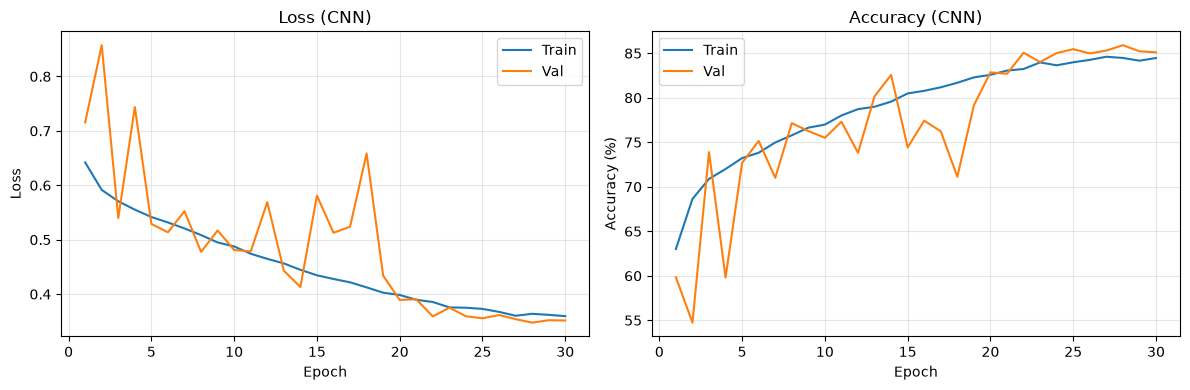

In [8]:
import matplotlib.pyplot as plt

epochs = range(1, len(train_losses) + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(epochs, train_losses, label='Train')
ax1.plot(epochs, val_losses, label='Val')
ax1.set_title('Loss (CNN)')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Loss')
ax1.legend()
ax1.grid(alpha=0.3)

ax2.plot(epochs, train_accuracies, label='Train')
ax2.plot(epochs, val_accuracies, label='Val')
ax2.set_title('Accuracy (CNN)')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Accuracy (%)')
ax2.legend()
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## Part 2: Transfer Learning


In [9]:
# Transfer learning models expect the native ImageNet resolution (224x224),
# so we rebuild the datasets/loaders for Part 2
img_width, img_height = 224, 224
batch_size = 32

data_transforms = {
    'train': transforms.Compose([
        transforms.RandomResizedCrop((img_width, img_height), scale=(0.6, 1.0)),
        transforms.RandomHorizontalFlip(),
        transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.05),
        transforms.ToTensor(),
        transforms.Normalize(imagenet_mean, imagenet_std),
    ]),
    'val': transforms.Compose([
        transforms.Resize(int(img_width * 1.14)),
        transforms.CenterCrop(img_width),
        transforms.ToTensor(),
        transforms.Normalize(imagenet_mean, imagenet_std),
    ]),
    'test': transforms.Compose([
        transforms.Resize(int(img_width * 1.14)),
        transforms.CenterCrop(img_width),
        transforms.ToTensor(),
        transforms.Normalize(imagenet_mean, imagenet_std),
    ]),
}

train_dataset = datasets.ImageFolder(train, transform=data_transforms['train'])
val_dataset = datasets.ImageFolder(val, transform=data_transforms['val'])
test_dataset = datasets.ImageFolder(test, transform=data_transforms['test'])

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=4,
                          pin_memory=True, persistent_workers=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, num_workers=4,
                        pin_memory=True, persistent_workers=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=4,
                         pin_memory=True, persistent_workers=True)


In [10]:
# First, download the weights of the VGG16 network trained on the ImageNet dataset:
vgg16_net = models.vgg16(pretrained=True)  # Load pre-trained VGG16
# Remove the classifier (fully connected layers) - we take only the "convolution" part
vgg16_net = vgg16_net.features  # Extract only convolutional features

# Freeze all convolutional weights ...
for param in vgg16_net.parameters():
    param.requires_grad = False

# ... but unfreeze the last convolutional block (conv5_x) so it can adapt to cats/dogs
for param in vgg16_net[24:].parameters():
    param.requires_grad = True

print(vgg16_net)  # pay attention to the architecture


C:\Users\Nikita\projects\2026-MLT\venv\Lib\site-packages\torchvision\models\_utils.py:207: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
C:\Users\Nikita\projects\2026-MLT\venv\Lib\site-packages\torchvision\models\_utils.py:222: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=VGG16_Weights.IMAGENET1K_V1`. You can also use `weights=VGG16_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Sequential(
  (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): ReLU(inplace=True)
  (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (3): ReLU(inplace=True)
  (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (5): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (6): ReLU(inplace=True)
  (7): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (8): ReLU(inplace=True)
  (9): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (10): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (11): ReLU(inplace=True)
  (12): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (13): ReLU(inplace=True)
  (14): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (15): ReLU(inplace=True)
  (16): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (17): Conv2d(256, 512, kernel_si

In [11]:
# Build transfer learning model by adding fully connected layers to VGG16

class VGG16TransferModel(nn.Module):
    def __init__(self, vgg16_features):
        super(VGG16TransferModel, self).__init__()
        self.features = vgg16_features  # Pre-trained VGG16 features

        # Adaptive pooling to handle feature input sizes
        # That operation shrinks the feature map size to 7x7
        self.avgpool = nn.AdaptiveAvgPool2d((7, 7))

        # Flattening (done in forward)
        # Dense fully connected layer with 256 neurons
        self.fc1 = nn.Linear(512 * 7 * 7, 256)  # VGG16 outputs 512 channels
        self.relu = nn.ReLU()

        # Dropout
        self.dropout = nn.Dropout(0.5)

        # Dense layer with 1 neuron (no sigmoid if using BCEWithLogitsLoss)
        self.fc2 = nn.Linear(256, 1)

    def forward(self, x):
        x = self.features(x)
        x = self.avgpool(x)
        x = torch.flatten(x, 1)  # Flatten

        x = self.fc1(x)
        x = self.relu(x)
        x = self.dropout(x)
        x = self.fc2(x)

        return x


model = VGG16TransferModel(vgg16_net).to(device)
print(model)

VGG16TransferModel(
  (features): Sequential(
    (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU(inplace=True)
    (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU(inplace=True)
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (5): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (6): ReLU(inplace=True)
    (7): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (8): ReLU(inplace=True)
    (9): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (10): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): ReLU(inplace=True)
    (12): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (13): ReLU(inplace=True)
    (14): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (15): ReLU(inplace=True)
    (16): MaxPool2d(kernel_size=2, stride=2, paddin

In [12]:
# Define loss and optimizer for transfer learning model
criterion = nn.BCEWithLogitsLoss()

num_epochs_transfer = 5

# Different learning rates: the pre-trained conv block is fine-tuned gently,
# the new classifier is trained from scratch with a larger LR
optimizer = optim.AdamW([
    {'params': [p for p in model.features[24:].parameters() if p.requires_grad], 'lr': 1e-4},
    {'params': model.fc1.parameters(), 'lr': 1e-3},
    {'params': model.fc2.parameters(), 'lr': 1e-3},
], weight_decay=1e-4)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=num_epochs_transfer)
scaler = torch.amp.GradScaler('cuda', enabled=device.type == 'cuda')


In [13]:
train_losses_transfer = []
train_accuracies_transfer = []
val_losses_transfer = []
val_accuracies_transfer = []

use_amp = device.type == 'cuda'

for epoch in range(num_epochs_transfer):
    model.train()
    running_loss, correct, total = 0.0, 0, 0
    for images, labels in train_loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True).float().unsqueeze(1)
        optimizer.zero_grad(set_to_none=True)
        with torch.amp.autocast('cuda', enabled=use_amp):
            outputs = model(images)
            loss = criterion(outputs, labels)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        running_loss += loss.item()
        predicted = (torch.sigmoid(outputs.float()) > 0.5).float()
        total += labels.size(0)
        correct += (predicted == labels).sum().item()
    scheduler.step()
    train_losses_transfer.append(running_loss / len(train_loader))
    train_accuracies_transfer.append(100 * correct / total)

    model.eval()
    val_running_loss, val_correct, val_total = 0.0, 0, 0
    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True).float().unsqueeze(1)
            with torch.amp.autocast('cuda', enabled=use_amp):
                outputs = model(images)
                loss = criterion(outputs, labels)
            val_running_loss += loss.item()
            predicted = (torch.sigmoid(outputs.float()) > 0.5).float()
            val_total += labels.size(0)
            val_correct += (predicted == labels).sum().item()
    val_losses_transfer.append(val_running_loss / len(val_loader))
    val_accuracies_transfer.append(100 * val_correct / val_total)

    print(f'Epoch [{epoch + 1}/{num_epochs_transfer}], '
          f'Train Loss: {train_losses_transfer[-1]:.4f}, Train Acc: {train_accuracies_transfer[-1]:.2f}%, '
          f'Val Loss: {val_losses_transfer[-1]:.4f}, Val Acc: {val_accuracies_transfer[-1]:.2f}%')

vgg16_history = {
    'train_losses': train_losses_transfer,
    'train_accuracies': train_accuracies_transfer,
    'val_losses': val_losses_transfer,
    'val_accuracies': val_accuracies_transfer,
}


Epoch [1/5], Train Loss: 0.0693, Train Acc: 97.69%, Val Loss: 0.1523, Val Acc: 95.78%


Epoch [2/5], Train Loss: 0.0365, Train Acc: 98.75%, Val Loss: 0.0455, Val Acc: 98.43%


Epoch [3/5], Train Loss: 0.0263, Train Acc: 99.12%, Val Loss: 0.0364, Val Acc: 99.04%


Epoch [4/5], Train Loss: 0.0159, Train Acc: 99.43%, Val Loss: 0.0435, Val Acc: 98.63%


Epoch [5/5], Train Loss: 0.0100, Train Acc: 99.63%, Val Loss: 0.0346, Val Acc: 99.04%


In [14]:
vgg16_test_acc = predict_loader(model, test_loader)
vgg16_model = model
print(f"VGG16 accuracy on test data (TTA): {vgg16_test_acc:.2f}%")


VGG16 accuracy on test data (TTA): 98.56%


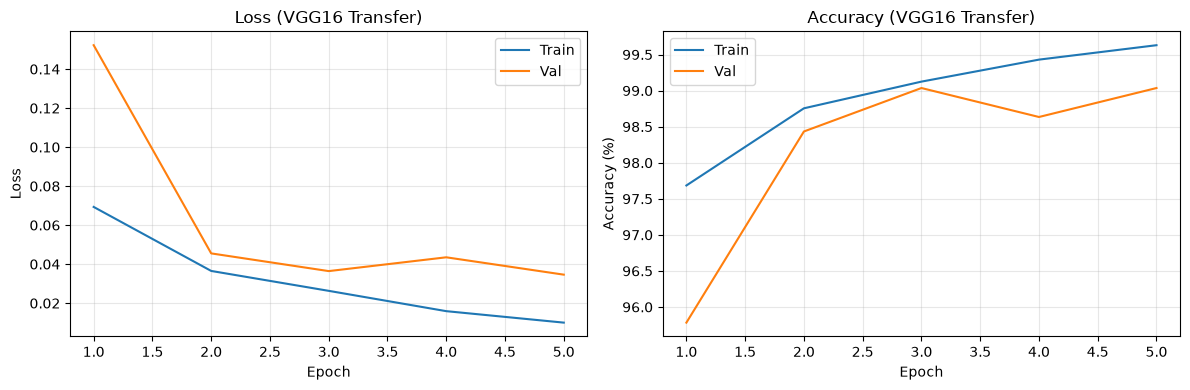

In [15]:
epochs = range(1, len(train_losses_transfer) + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(epochs, train_losses_transfer, label='Train')
ax1.plot(epochs, val_losses_transfer, label='Val')
ax1.set_title('Loss (VGG16 Transfer)')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Loss')
ax1.legend()
ax1.grid(alpha=0.3)

ax2.plot(epochs, train_accuracies_transfer, label='Train')
ax2.plot(epochs, val_accuracies_transfer, label='Val')
ax2.set_title('Accuracy (VGG16 Transfer)')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Accuracy (%)')
ax2.legend()
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### ResNet18


In [16]:
resnet = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
for param in resnet.parameters():
    param.requires_grad = False

# Fine-tune the last two residual stages together with the new classifier
for param in resnet.layer3.parameters():
    param.requires_grad = True
for param in resnet.layer4.parameters():
    param.requires_grad = True

resnet.fc = nn.Sequential(
    nn.Linear(resnet.fc.in_features, 256),
    nn.ReLU(),
    nn.Dropout(0.5),
    nn.Linear(256, 1)
)

model = resnet.to(device)
criterion = nn.BCEWithLogitsLoss()

num_epochs_transfer = 5
optimizer = optim.AdamW([
    {'params': model.layer3.parameters(), 'lr': 1e-5},
    {'params': model.layer4.parameters(), 'lr': 1e-4},
    {'params': model.fc.parameters(), 'lr': 1e-3},
], weight_decay=1e-4)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=num_epochs_transfer)
scaler = torch.amp.GradScaler('cuda', enabled=device.type == 'cuda')

train_losses_resnet, train_accuracies_resnet = [], []
val_losses_resnet, val_accuracies_resnet = [], []

use_amp = device.type == 'cuda'

for epoch in range(num_epochs_transfer):
    model.train()
    running_loss, correct, total = 0.0, 0, 0
    for images, labels in train_loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True).float().unsqueeze(1)
        optimizer.zero_grad(set_to_none=True)
        with torch.amp.autocast('cuda', enabled=use_amp):
            outputs = model(images)
            loss = criterion(outputs, labels)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        running_loss += loss.item()
        predicted = (torch.sigmoid(outputs.float()) > 0.5).float()
        total += labels.size(0)
        correct += (predicted == labels).sum().item()
    scheduler.step()
    train_losses_resnet.append(running_loss / len(train_loader))
    train_accuracies_resnet.append(100 * correct / total)

    model.eval()
    val_running_loss, val_correct, val_total = 0.0, 0, 0
    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True).float().unsqueeze(1)
            with torch.amp.autocast('cuda', enabled=use_amp):
                outputs = model(images)
                loss = criterion(outputs, labels)
            val_running_loss += loss.item()
            predicted = (torch.sigmoid(outputs.float()) > 0.5).float()
            val_total += labels.size(0)
            val_correct += (predicted == labels).sum().item()
    val_losses_resnet.append(val_running_loss / len(val_loader))
    val_accuracies_resnet.append(100 * val_correct / val_total)

    print(f'Epoch [{epoch + 1}/{num_epochs_transfer}], '
          f'Train Loss: {train_losses_resnet[-1]:.4f}, Train Acc: {train_accuracies_resnet[-1]:.2f}%, '
          f'Val Loss: {val_losses_resnet[-1]:.4f}, Val Acc: {val_accuracies_resnet[-1]:.2f}%')

resnet_history = {
    'train_losses': train_losses_resnet,
    'train_accuracies': train_accuracies_resnet,
    'val_losses': val_losses_resnet,
    'val_accuracies': val_accuracies_resnet,
}


Epoch [1/5], Train Loss: 0.0699, Train Acc: 97.25%, Val Loss: 0.0372, Val Acc: 98.71%


Epoch [2/5], Train Loss: 0.0405, Train Acc: 98.55%, Val Loss: 0.0323, Val Acc: 98.76%


Epoch [3/5], Train Loss: 0.0273, Train Acc: 99.08%, Val Loss: 0.0313, Val Acc: 98.92%


Epoch [4/5], Train Loss: 0.0161, Train Acc: 99.42%, Val Loss: 0.0422, Val Acc: 98.59%


Epoch [5/5], Train Loss: 0.0140, Train Acc: 99.47%, Val Loss: 0.0341, Val Acc: 98.96%


ResNet18 accuracy on test data (TTA): 98.60%


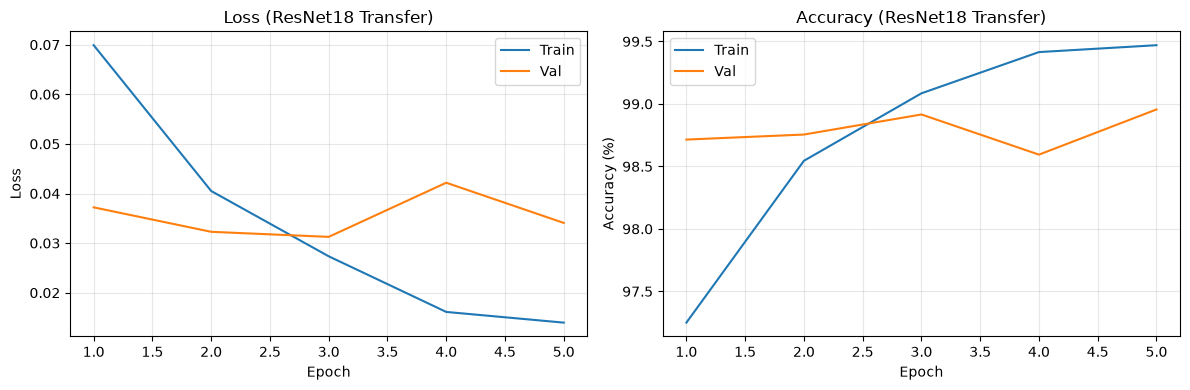

,Test Accuracy (%)
Model,
CNN (from scratch),86.24
VGG16 Transfer,98.56
ResNet18 Transfer,98.60


In [17]:
resnet_test_acc = predict_loader(model, test_loader)
resnet_model = model
print(f"ResNet18 accuracy on test data (TTA): {resnet_test_acc:.2f}%")

epochs = range(1, len(resnet_history['train_losses']) + 1)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(epochs, resnet_history['train_losses'], label='Train')
ax1.plot(epochs, resnet_history['val_losses'], label='Val')
ax1.set_title('Loss (ResNet18 Transfer)')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Loss')
ax1.legend()
ax1.grid(alpha=0.3)

ax2.plot(epochs, resnet_history['train_accuracies'], label='Train')
ax2.plot(epochs, resnet_history['val_accuracies'], label='Val')
ax2.set_title('Accuracy (ResNet18 Transfer)')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Accuracy (%)')
ax2.legend()
ax2.grid(alpha=0.3)
plt.tight_layout()
plt.show()

import pandas as pd

comparison_df = pd.DataFrame([
    {'Model': 'CNN (from scratch)', 'Test Accuracy (%)': round(test_accuracy, 2)},
    {'Model': 'VGG16 Transfer', 'Test Accuracy (%)': round(vgg16_test_acc, 2)},
    {'Model': 'ResNet18 Transfer', 'Test Accuracy (%)': round(resnet_test_acc, 2)},
]).set_index('Model')
comparison_df


## Inference


Best model: ResNet18


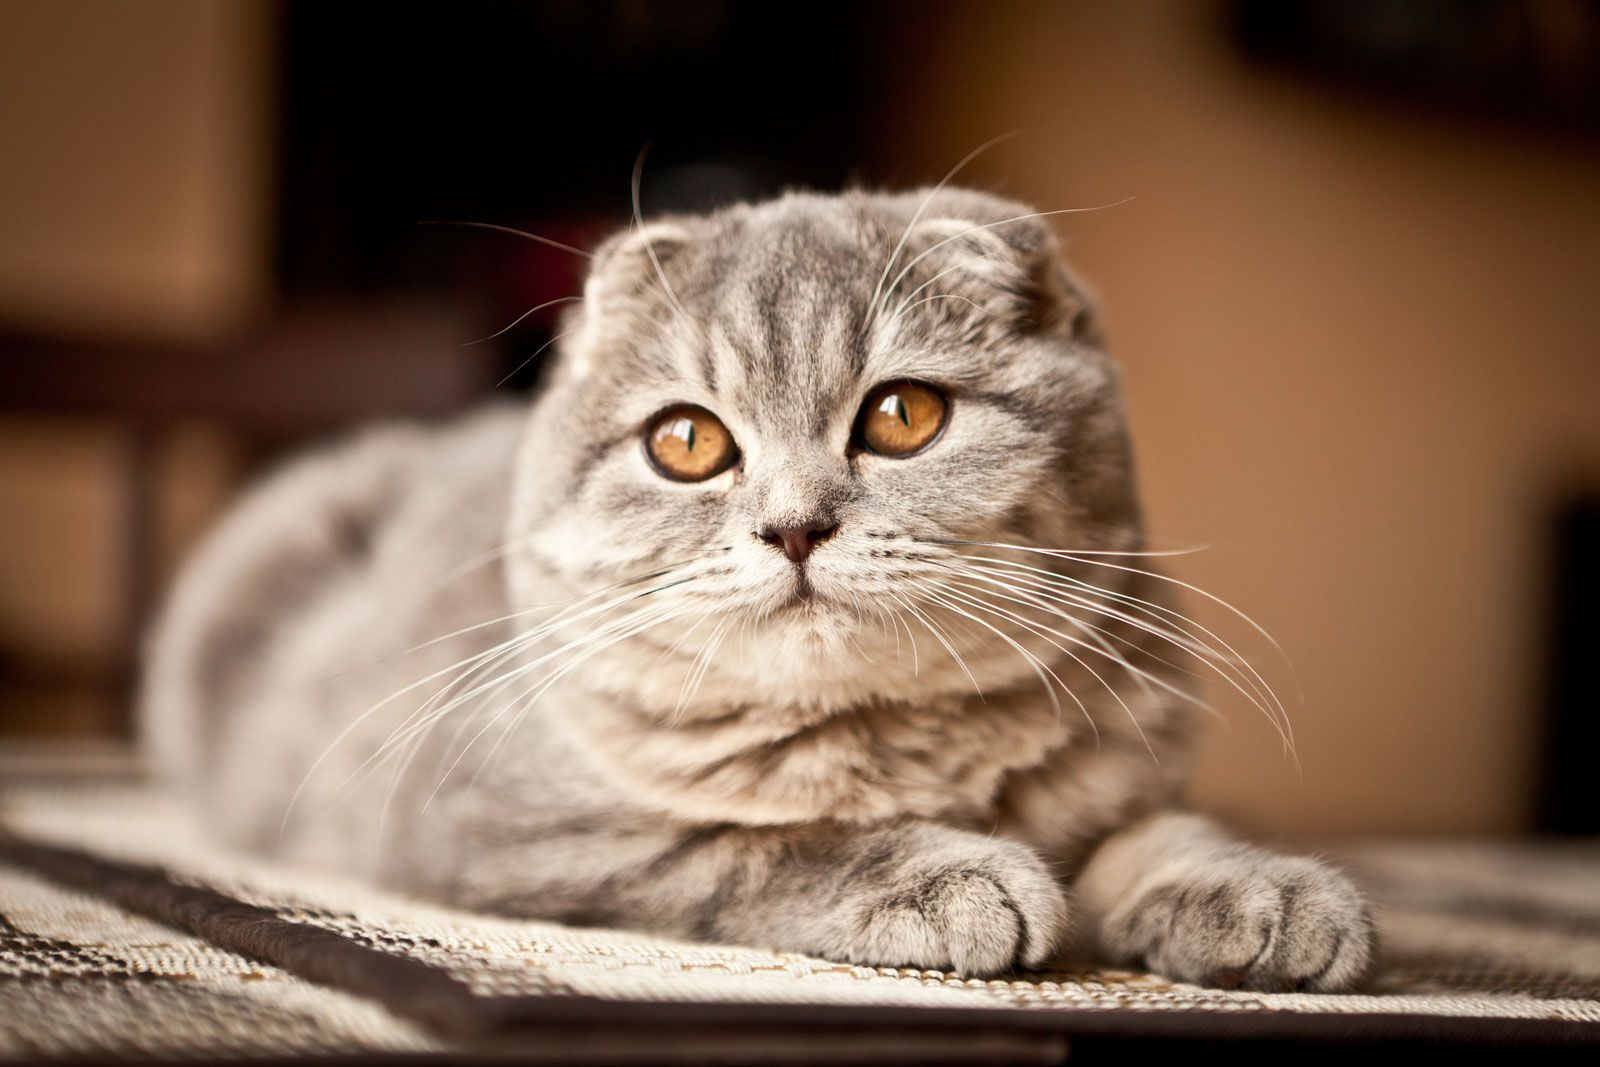

Prediction: cats
  cats: 100.00%
  dogs: 0.00%


In [18]:
from PIL import Image
from IPython.display import display, Image as IPImage


def predict_image(image_path, model, device, tta=True):
    """Return the predicted class and the per-class probabilities for one image."""
    class_names = train_dataset.classes
    image = Image.open(image_path).convert('RGB')
    transform = transforms.Compose([
        transforms.Resize((img_width, img_height)),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
    ])
    x = transform(image).unsqueeze(0).to(device)

    model.eval()
    with torch.no_grad():
        prob_dog = torch.sigmoid(model(x)).item()
        if tta:  # average with the horizontally flipped image
            prob_dog = (prob_dog + torch.sigmoid(model(torch.flip(x, dims=[3]))).item()) / 2

    probabilities = {class_names[0]: 1 - prob_dog, class_names[1]: prob_dog}
    return max(probabilities, key=probabilities.get), probabilities


best_model, best_name = (vgg16_model, 'VGG16') if vgg16_test_acc >= resnet_test_acc else (resnet_model, 'ResNet18')
print(f"Best model: {best_name}")


image_path = 'Scottish-fold-cat.jpg'
display(IPImage(filename=image_path, width=320))
label, probabilities = predict_image(image_path, best_model, device)
print(f"Prediction: {label}")
for class_name, probability in probabilities.items():
    print(f"  {class_name}: {probability * 100:.2f}%")
